# Bayesian Weibull model to compare two groups

We compare the survival times of two groups with a Weibull model, first by maximum likelihood with `lifelines` and then with a Bayesian model in `pymc`. The Bayesian model gives the whole posterior distribution of any quantity we are interested in: the hazard ratio, the survivor and hazard functions of each group, and the median survival times.

The data are the survival times, in months, of 45 women with breast cancer. The tumours were stained with a marker (HPA) and classified as negatively or positively stained. Is a positive staining associated with a shorter survival?

In [1]:
import numpy as np
import pandas as pd
import xarray as xr

import pymc as pm
import arviz as az

import matplotlib.pyplot as plt

from lifelines import KaplanMeierFitter, WeibullAFTFitter

In [2]:
ALPHA = 0.05 # Significance level for the prediction intervals
SEED = 111   # For reproducible results

T_VECT = np.linspace(0, 250) # Time to evaluate the estimated survivor functions

In [3]:
# Colors shared by all the plots
GROUPS = ["Stain Negative", "Stain Positive"]
GROUP_COLORS = ['#1f4e79', '#E69F00']
point_color = '#c1121f'
line_color  = '#1f4e79'
pi_color    = '#cfe8f3'
opt_color   = '#E69F00'
ref_color   = '#333333'

interval_label = f'{(1 - ALPHA) * 100:.0f}% highest density interval'

## Reading and preprocessing the data

In [4]:
DatOriginal = pd.read_csv("data/breast_cancer_prognosis.dat", sep=r"\s+")
DatOriginal["stain"] = pd.get_dummies(DatOriginal["stain"], drop_first=True, dtype=int)

In [5]:
DatOriginal.head()

,stain,time,status
0,0,23,1
1,0,47,1
2,0,69,1
3,0,70,0
4,0,71,0


In [6]:
DatOriginal.groupby("stain").agg(women=("time", "size"), deaths=("status", "sum"), censored=("status", lambda s: (1-s).sum()))

,women,deaths,censored
stain,,,
0,13,5,8
1,32,21,11


## Functions

The Weibull distribution with shape $\rho$ and scale $\lambda$ has

$$
S(t)=\exp\left\{-\left(\frac{t}{\lambda}\right)^\rho\right\},\qquad
h(t)=\frac{\rho}{\lambda^\rho}\,t^{\rho-1},\qquad
t(p)=\lambda\{-\log(1-p)\}^{1/\rho}.
$$

The hazard increases with time if $\rho>1$, decreases if $\rho<1$, and is constant (exponential distribution) if $\rho=1$.

In [7]:
# Weibull log-hazard function
def WeibullLogHazard(t, rho, lam):
    return -rho*np.log(lam) + np.log(rho) + (rho-1)*np.log(t)

# Weibull hazard function
def WeibullHazard(t, rho, lam):
    return np.exp(WeibullLogHazard(t, rho, lam))

# Weibull log-survivor function
def WeibullLogSurvivor(t, rho, lam):
    return (-(t/lam)**rho)

# Weibull survivor function
def WeibullSurvivor(t, rho, lam):
    return np.exp(WeibullLogSurvivor(t, rho, lam))

In [8]:
# Time quantile
def TimeQuantile(p, rho, lam):
    return lam * (-np.log(1-p))**(1/rho)

Functions to calculate the posterior mean and the credible interval of the survivor and hazard functions of a group. The function is evaluated at every time for each draw of the posterior distribution.

In [9]:
def CalculatePosteriorFunction(function, t_vect, trace, group):
    t = xr.DataArray(t_vect, dims="time", coords={"time": t_vect})
    draws = function(t, trace.posterior["Rho"], trace.posterior["Lambda"].isel(group=group))
    interval = az.hdi(draws.rename("function"), hdi_prob=1-ALPHA)["function"]

    return pd.DataFrame(
        {
            "mean": draws.mean(("chain", "draw")).to_numpy(),
            "lower": interval.sel(hdi="lower").to_numpy(),
            "upper": interval.sel(hdi="higher").to_numpy()
        },
        index=t_vect
    )

def CalculateSurvivorFunction(t_vect, trace, group):
    return CalculatePosteriorFunction(WeibullSurvivor, t_vect, trace, group)

def CalculateHazardFunction(t_vect, trace, group):
    return CalculatePosteriorFunction(WeibullHazard, t_vect, trace, group)

Functions for the plots.

In [10]:
def PlotKm(ax, km_estimate, color, label, band=True):
    # Kaplan-Meier estimator as a step function, with a tick at each censored time
    surv = km_estimate.survival_function_.iloc[:, 0]
    if band:
        ci = km_estimate.confidence_interval_
        ax.fill_between(ci.index, ci.iloc[:, 0], ci.iloc[:, 1], step='post', color=color, alpha=0.25, lw=0)
    ax.step(surv.index, surv, where='post', color=color, lw=2, label=label)
    censored = km_estimate.event_table.index[km_estimate.event_table['censored'] > 0]
    ax.plot(censored, surv.loc[censored], '|', color=color, markersize=11, markeredgewidth=2)

def PlotCurve(ax, curve, color, label=None, band=True, ls='-'):
    # Posterior mean of a function of time, with its credible interval
    if band:
        ax.fill_between(curve.index, curve["lower"], curve["upper"], color=color, alpha=0.25, lw=0)
    ax.plot(curve.index, curve["mean"], color=color, lw=2, ls=ls, label=label)

def PlotKmAndSurvivorSideBySide(surv_0, surv_1, km_estimate_0, km_estimate_1):

    fig, ax = plt.subplots(1, 2, figsize=(16, 7), sharex=True, sharey=True)

    # First plot
    # Plot the Kaplan-Meier estimators
    PlotKm(ax[0], km_estimate_0, GROUP_COLORS[0], GROUPS[0])
    PlotKm(ax[0], km_estimate_1, GROUP_COLORS[1], GROUPS[1])

    # Second plot
    # Plot the Weibull model
    PlotCurve(ax[1], surv_0, GROUP_COLORS[0], GROUPS[0])
    PlotCurve(ax[1], surv_1, GROUP_COLORS[1], GROUPS[1])

    # General options for the plot
    ax[0].legend(loc='lower left', frameon=False)
    ax[0].set_ylabel("Survivor function")
    ax[0].set_ylim(0, 1.02)
    ax[0].set_xlim(0, T_VECT[-1])
    ax[0].set_title(f"Kaplan-Meier estimator\n({(1 - ALPHA) * 100:.0f}% confidence interval, ticks are censored times)")
    ax[1].set_title(f"Weibull model\n(posterior mean and {interval_label})")
    for a in ax:
        a.set_xlabel("Time (months)")
        a.grid(True, alpha=0.25)
    plt.tight_layout()

def PlotKmAndSurvivorSamePlot(surv_0, surv_1, km_estimate_0, km_estimate_1):

    fig, ax = plt.subplots(figsize=(10, 7.5))

    # Plot the Kaplan-Meier estimators
    PlotKm(ax, km_estimate_0, GROUP_COLORS[0], None, band=False)
    PlotKm(ax, km_estimate_1, GROUP_COLORS[1], None, band=False)

    # Plot the Weibull model
    PlotCurve(ax, surv_0, GROUP_COLORS[0], GROUPS[0])
    PlotCurve(ax, surv_1, GROUP_COLORS[1], GROUPS[1])

    # General options for the plot
    ax.legend(loc='lower left', frameon=False)
    ax.set_xlabel("Time (months)")
    ax.set_ylabel("Survivor function")
    ax.set_ylim(0, 1.02)
    ax.set_xlim(0, T_VECT[-1])
    ax.set_title("The Weibull model follows the Kaplan-Meier estimator of each group\n"
                 "(steps: Kaplan-Meier, curves: Weibull model)")
    ax.grid(True, alpha=0.25)

def PlotHazardSamePlot(hazard_0, hazard_1):

    fig, ax = plt.subplots(figsize=(10, 7.5))

    PlotCurve(ax, hazard_0, GROUP_COLORS[0], GROUPS[0])
    PlotCurve(ax, hazard_1, GROUP_COLORS[1], GROUPS[1])

    # General options for the plot
    ax.legend(loc='upper right', frameon=False)
    ax.set_xlabel("Time (months)")
    ax.set_ylabel("Hazard function (deaths per woman per month)")
    ax.set_xlim(0, T_VECT[-1])
    ax.set_ylim(0, None)
    ax.set_title(f"The hazard is higher for the positively stained tumours at all times\n(posterior mean and {interval_label})")
    ax.grid(True, alpha=0.25)

def PlotPosterior(ax, draws, limits, color=pi_color, median_color=line_color, interval_color=opt_color, alpha=1):
    # Histogram of the posterior draws with the median and the credible interval.
    # The posterior distributions have long tails, we show the central part.
    draws = np.asarray(draws).ravel()
    median = np.median(draws)
    low, upp = az.hdi(draws, hdi_prob=1-ALPHA)
    ax.hist(draws, bins=np.linspace(limits[0], limits[1], 61), density=True, color=color, alpha=alpha, edgecolor='white',
            linewidth=0.5, label='Posterior draws')
    ax.axvline(median, color=median_color, lw=2, label='Posterior median')
    ax.plot([low, min(upp, limits[1])], [0, 0], color=interval_color, lw=7, solid_capstyle='butt', clip_on=False, zorder=5,
            label=interval_label)
    ax.set_xlim(limits)
    ax.set_yticks([])
    ax.grid(True, axis='x', alpha=0.25)
    return median, low, upp

## Fit Weibull AFT model using `lifelines`

In this case $\rho=\exp(\mu_\rho)$, and $\log\lambda(x)=\mu_\lambda+\beta x$, where $x=1$ for the positively stained tumours.

Thus, the hazard ratio is given by $\psi=e^{-\rho\beta}$

In [11]:
aft = WeibullAFTFitter(alpha=ALPHA)
aft.fit(DatOriginal, 'time', event_col='status')

<lifelines.WeibullAFTFitter: fitted with 45 total observations, 19 right-censored observations>

In [12]:
aft.print_summary()

<lifelines.WeibullAFTFitter: fitted with 45 total observations, 19 right-censored observations>
             duration col = 'time'
                event col = 'status'
   number of observations = 45
number of events observed = 26
           log-likelihood = -156.75
         time fit was run = 2026-10-13 01:53:33 UTC

---
                   coef exp(coef)  se(coef)  coef lower 95%  coef upper 95% exp(coef) lower 95% exp(coef) upper 95%
param   covariate                                                                                                  
lambda_ stain     -1.00      0.37      0.54           -2.06            0.07                0.13                1.07
        Intercept  5.85    348.76      0.50            4.88            6.83              131.18              927.22
rho_    Intercept -0.06      0.94      0.17           -0.39            0.26                0.68                1.30

                   cmp to     z      p  -log2(p)
param   covariate                               
lambda_ stain        0.00 -1.83   0.07      3.90
        Intercept    0.00 11.73 <0.005    103.22
rho_    Intercept    0.00 -0.39   0.70      0.52
---
Concordance = 0.60
AIC = 319.49
log-likelihood ratio test = 4.14 on 1 df
-log2(p) of ll-ratio test = 4.58

In [13]:
#Rho
Rho_aft = aft.summary["exp(coef)"]["rho_"]["Intercept"]

round(Rho_aft, 4)

np.float64(0.9374)

In [14]:
#Hazard ratio
Psi_aft = np.exp(-Rho_aft * aft.summary["coef"]["lambda_"]["stain"])
round(Psi_aft, 4)

np.float64(2.5454)

## Fit Weibull model using Bayesian statistics

Each group $g$ (0 for negative, 1 for positive staining) has its own scale, and the two groups share the shape:

$$
\begin{align*}
T|\lambda_g,\rho &\sim \textsf{Weibull}(\lambda_g,\rho) \\
\lambda_g &= \exp\{\beta_g\},\quad g=0,1 \\
\beta_g &\sim \textsf{Normal}(0,10),\quad g=0,1 \\
\rho &\sim \textsf{HalfNormal}(10)
\end{align*}
$$

The hazard ratio of the positive group against the negative one is $\psi=(\lambda_0/\lambda_1)^\rho=\exp\{-\rho(\beta_1-\beta_0)\}$.

An observed time contributes to the likelihood with the density, and a censored time with the survivor function.

In [15]:
y = DatOriginal["time"].values
ev = (DatOriginal["status"]==1).values
stain = DatOriginal["stain"].values

with pm.Model(coords={"group": GROUPS}) as WeibullRegression:
    # Regression
    Beta = pm.Normal("Beta", mu=0, sigma=10, dims="group")

    # Weibull parameters
    Rho = pm.HalfNormal("Rho", sigma=10)
    Lambda = pm.Deterministic("Lambda", np.exp(Beta), dims="group")

    # Hazard ratio
    Psi = pm.Deterministic("HazardRatio", np.exp(-Rho* (Beta[1]-Beta[0])))

    # Time quantile
    MedianTime = pm.Deterministic("MedianTime", TimeQuantile(0.5, Rho, Lambda), dims="group")

    # Log-likelihood
    Logdensity = pm.Weibull("TimesObserved", Rho, Lambda[stain[ev]], observed=y[ev])
    Logsurvivor = pm.Potential("TimesCensored", WeibullLogSurvivor(y[~ev], Rho, Lambda[stain[~ev]]))

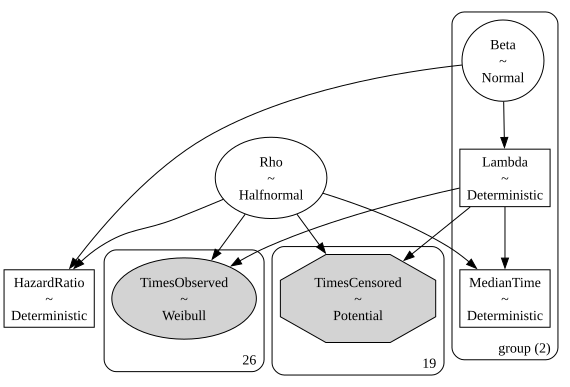

In [16]:
pm.model_to_graphviz(WeibullRegression)

In [17]:
with WeibullRegression:
    TraceWeibull = pm.sample(random_seed=SEED)

Initializing NUTS using jitter+adapt_diag...


Multiprocess sampling (4 chains in 4 jobs)


NUTS: [Beta, Rho]


Output()

Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 31 seconds.


In [18]:
Summary = az.summary(
    TraceWeibull,
    var_names=["Rho", "Beta", "Lambda", "MedianTime", "HazardRatio"],
    kind="stats",
    stat_focus="median",
    hdi_prob=1-ALPHA
)

Summary

,median,mad,eti_2.5%,eti_97.5%
Rho,0.897,0.105,0.631,1.250
Beta[Stain Negative],5.944,0.357,5.099,7.314
Beta[Stain Positive],4.894,0.170,4.435,5.465
Lambda[Stain Negative],381.441,127.152,163.867,1501.797
Lambda[Stain Positive],133.551,22.375,84.384,236.377
MedianTime[Stain Negative],254.693,83.095,108.674,931.991
MedianTime[Stain Positive],89.470,15.192,53.883,150.374
HazardRatio,2.612,0.843,1.084,7.831


### The hazard ratio

A hazard ratio of 1 means that the two groups have the same hazard.

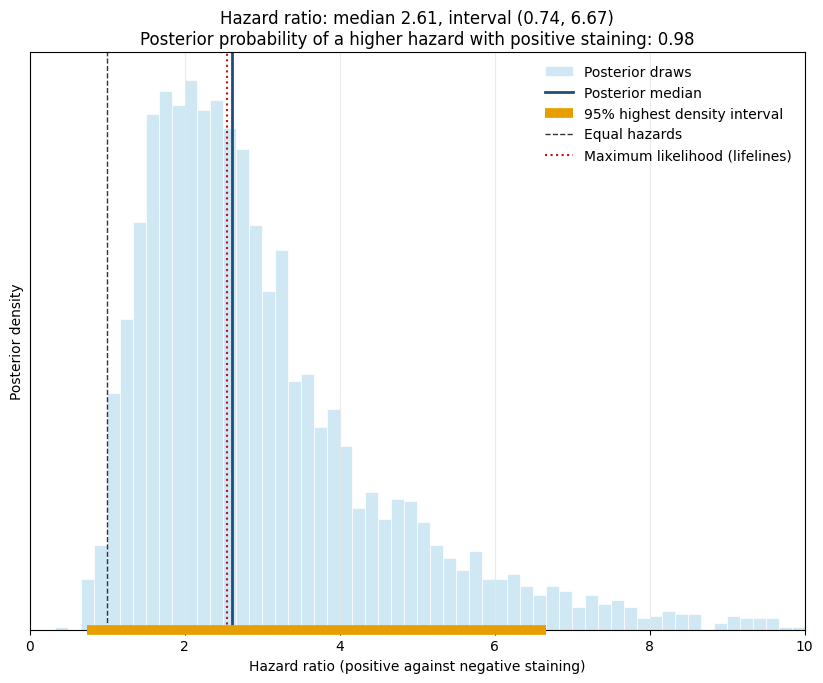

In [19]:
HazardRatioDraws = TraceWeibull.posterior["HazardRatio"].to_numpy().ravel()

fig, ax = plt.subplots(figsize=(10, 7.5))
median, low, upp = PlotPosterior(ax, HazardRatioDraws, (0, 10))
ax.axvline(1, color=ref_color, lw=1, ls='--', label='Equal hazards')
ax.axvline(Psi_aft, color=point_color, lw=1.5, ls=':', label='Maximum likelihood (lifelines)')

ax.set_xlabel('Hazard ratio (positive against negative staining)')
ax.set_ylabel('Posterior density')
ax.set_title(f'Hazard ratio: median {median:.2f}, interval ({low:.2f}, {upp:.2f})\n'
             f'Posterior probability of a higher hazard with positive staining: {(HazardRatioDraws > 1).mean():.2f}')
ax.legend(loc='upper right', frameon=False)

## Statistics of interest

Survivor functions, to compare them with the Kaplan-Meier estimator, and hazard functions.

In [20]:
DatOriginalNegative = DatOriginal[DatOriginal['stain']==0]
DatOriginalPositive = DatOriginal[DatOriginal['stain']==1]

In [21]:
# Kaplan-Meier estimators for the stain negative and positive
KmNegative = KaplanMeierFitter(alpha=ALPHA)
KmNegative.fit(DatOriginalNegative['time'], event_observed=DatOriginalNegative['status'])

KmPositive = KaplanMeierFitter(alpha=ALPHA)
KmPositive.fit(DatOriginalPositive['time'], event_observed=DatOriginalPositive['status'])

# Survivor function estimators for the stain negative and positive
SurvivorNegative = CalculateSurvivorFunction(T_VECT, TraceWeibull, 0)
SurvivorPositive = CalculateSurvivorFunction(T_VECT, TraceWeibull, 1)

# Hazard function estimators for the stain negative and positive
# (the hazard is not evaluated at zero, where it is infinite when rho < 1)
HazardNegative = CalculateHazardFunction(T_VECT[1:], TraceWeibull, 0)
HazardPositive = CalculateHazardFunction(T_VECT[1:], TraceWeibull, 1)

## Plotting statistics of interests

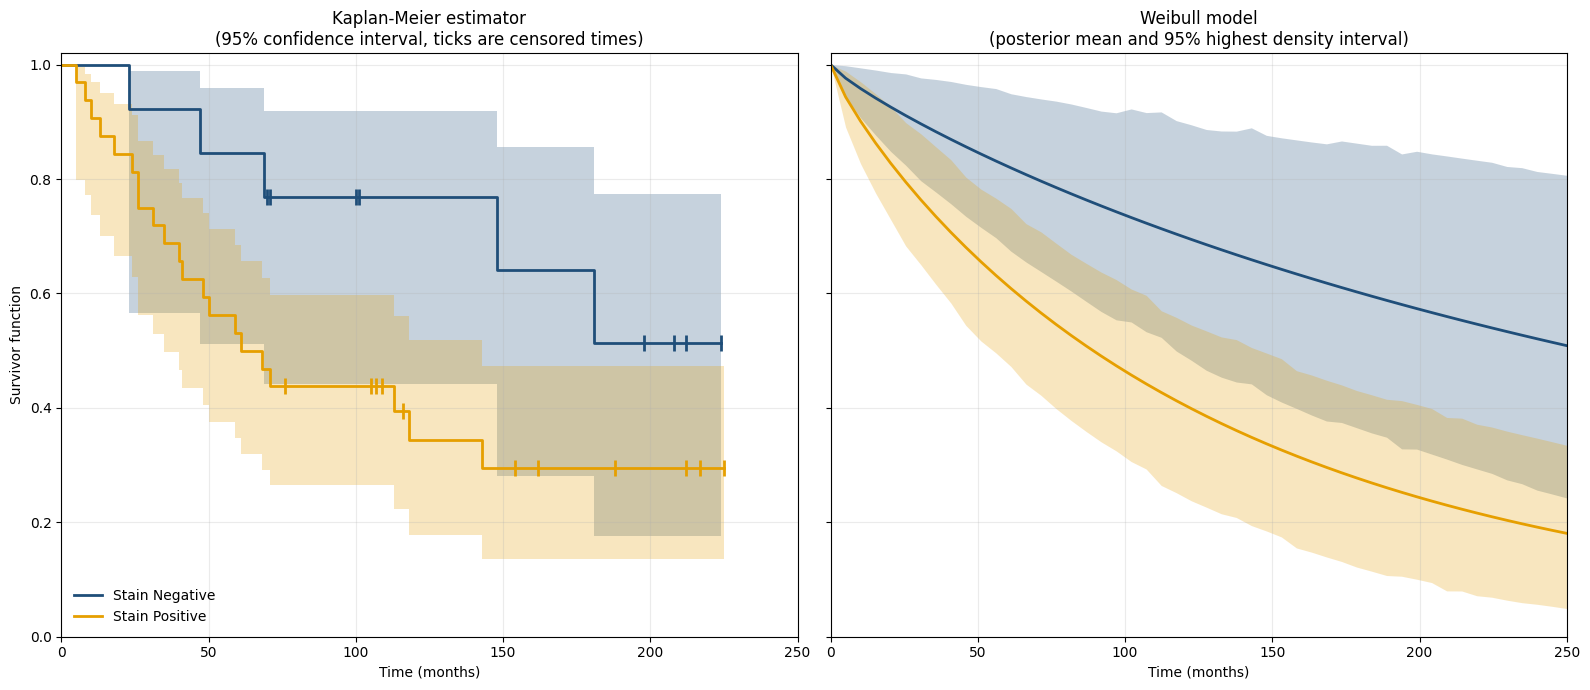

In [22]:
PlotKmAndSurvivorSideBySide(SurvivorNegative, SurvivorPositive, KmNegative, KmPositive)

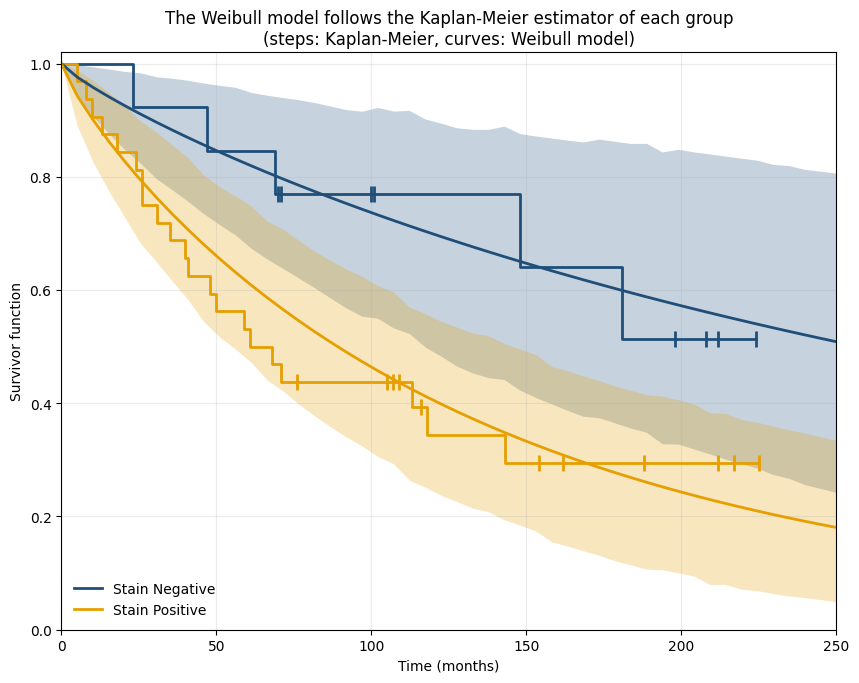

In [23]:
PlotKmAndSurvivorSamePlot(SurvivorNegative, SurvivorPositive, KmNegative, KmPositive)

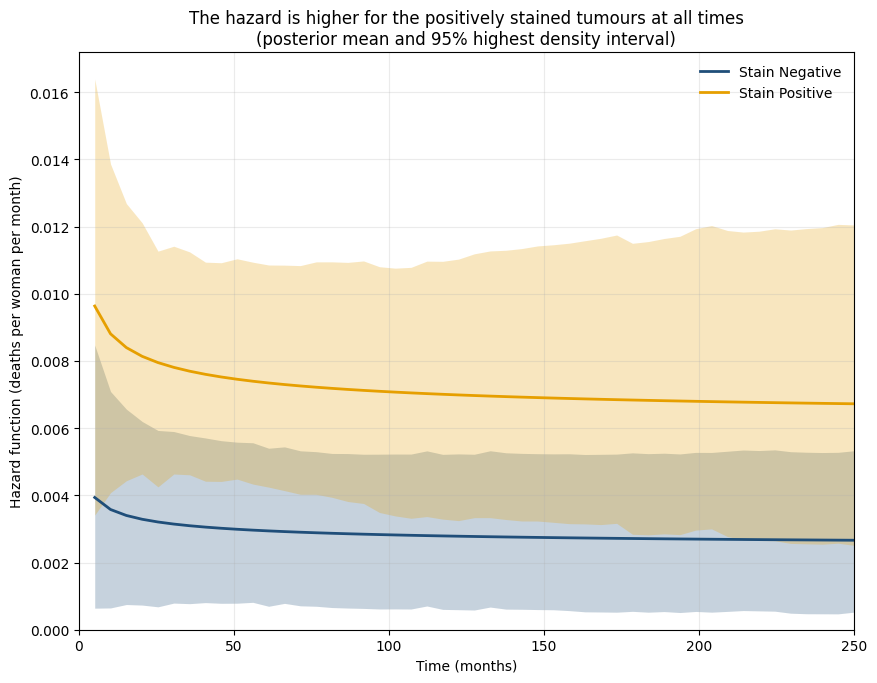

In [24]:
PlotHazardSamePlot(HazardNegative, HazardPositive)

Plot median survival times

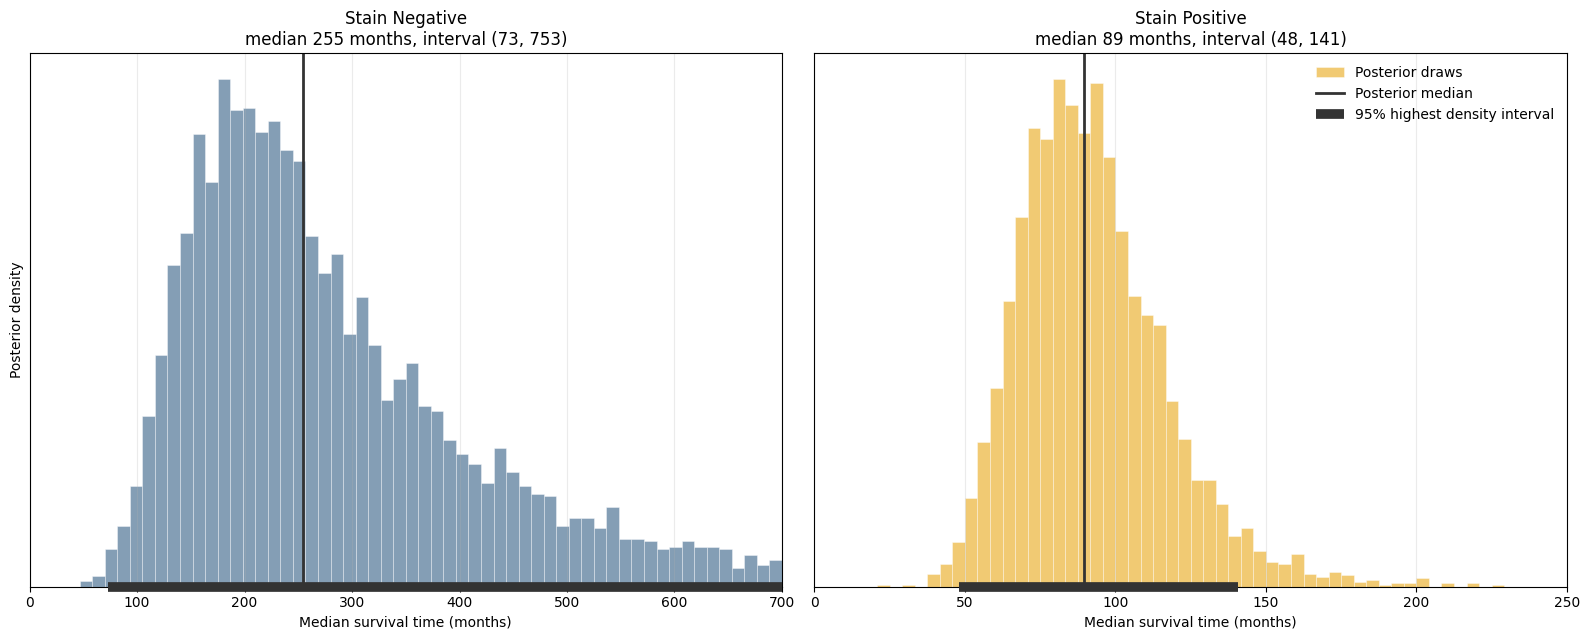

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6.5))
for g, (ax, limits) in enumerate(zip(axes, [(0, 700), (0, 250)])):
    median, low, upp = PlotPosterior(ax, TraceWeibull.posterior["MedianTime"].isel(group=g), limits,
                                     color=GROUP_COLORS[g], median_color=ref_color, interval_color=ref_color, alpha=0.55)
    ax.set_xlabel('Median survival time (months)')
    ax.set_title(f'{GROUPS[g]}\nmedian {median:.0f} months, interval ({low:.0f}, {upp:.0f})')
axes[0].set_ylabel('Posterior density')
axes[1].legend(loc='upper right', frameon=False)
plt.tight_layout()

The two posterior distributions in the same scale. The median survival time of the negative group is very uncertain: more than half of those women were still alive at the end of the study.

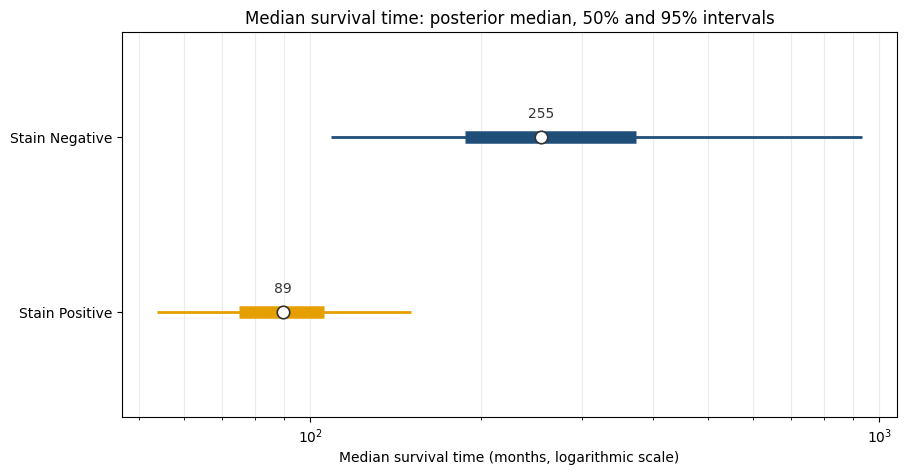

In [26]:
fig, ax = plt.subplots(figsize=(10, 5))
for g in range(2):
    draws = TraceWeibull.posterior["MedianTime"].isel(group=g).to_numpy().ravel()
    q = np.quantile(draws, [ALPHA/2, 0.25, 0.5, 0.75, 1-ALPHA/2])
    ax.plot([q[0], q[4]], [g, g], color=GROUP_COLORS[g], lw=2, solid_capstyle='butt')
    ax.plot([q[1], q[3]], [g, g], color=GROUP_COLORS[g], lw=9, solid_capstyle='butt')
    ax.plot(q[2], g, 'o', color='white', markersize=9, markeredgecolor=ref_color, markeredgewidth=1.2, zorder=5)
    ax.annotate(f'{q[2]:.0f}', (q[2], g), xytext=(0, 14), textcoords='offset points', ha='center', color=ref_color)

ax.set_xscale('log')
ax.set_yticks([0, 1], GROUPS)
ax.set_ylim(-0.6, 1.6)
ax.invert_yaxis()
ax.set_xlabel('Median survival time (months, logarithmic scale)')
ax.set_title(f'Median survival time: posterior median, 50% and {(1 - ALPHA) * 100:.0f}% intervals')
ax.grid(True, axis='x', which='both', alpha=0.25)